# Faza II – Detektimi i përjashtuesve, mënjanimi dhe eksplorimi

**Prokurimi publik në Shqipëri, 2016–2025** · Grupi 13 · Përgatitja dhe vizualizimi i të dhënave

Kërkesat e Fazës II:
- **Detektimi i përjashtuesve**: univariant (IQR, z-score i fortë me MAD) dhe multivariant (distanca Mahalanobis, kontroll me KNN);
- **Mënjanimi i zbulimeve jo të sakta**: ndarja e gabimeve reale nga vlerat e vërteta por të rralla, që këto të fundit të mos trajtohen gabimisht si përjashtues;
- **Eksplorimi i të dhënave**: statistika përmbledhëse dhe multivariante.

Çdo rresht mbetet në dataset. Përjashtuesit shënohen me `outlier_status`: **gabim**, **e vërtetë por e rrallë** ose **e pasigurt**.

Dokumentimi: [`docs/outliers.md`](../docs/outliers.md), [`docs/exploration.md`](../docs/exploration.md).

In [1]:
import os
import sys
from pathlib import Path

# Notebook-u ekzekutohet nga rrënja e repository-t, që të gjenden src/ dhe data/
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.dpi"] = 100

from src.common.data_loading import read_years
from src.final.final_dataset import build

df, _ = build(read_years())
print(f"Dataset-i final: {len(df):,} procedura x {df.shape[1]} kolona")

Dataset-i final: 277,764 procedura x 84 kolona


---
# 1. Pjesa e Semines: shumat dhe koha

Kodi: `src/outliers/amounts_time.py`. Përmbledhja e statuseve (nga `reports/outliers/`):

In [2]:
pd.read_csv("reports/outliers/amounts_time_outlier_summary.csv")

,column,outlier_status,procedures
0,Fondi_limit,gabim,5985
1,Fondi_limit,e vërtetë por e rrallë,11697
2,Fondi_limit,e pasigurt,9556
3,Fondi_limit,(nuk është përjashtues),250526
4,Vlera_e_fituesit,gabim,5993
5,Vlera_e_fituesit,e vërtetë por e rrallë,6504
6,Vlera_e_fituesit,e pasigurt,7302
7,Vlera_e_fituesit,(nuk është përjashtues),257965
8,Vlera_e_fituesit_ne_lidhjen_e_kontrates,gabim,1
9,Vlera_e_fituesit_ne_lidhjen_e_kontrates,e vërtetë por e rrallë,2690


### 1.1 Detektimi dhe mënjanimi i zbulimeve jo të sakta

IQR dhe z-score i fortë (MAD), globalisht dhe brenda `Lloji_i_procedures`, mbi shkallën log. Numrat janë rillogaritur këtu, direkt nga dataset-i final (jo thjesht kopjuar).

In [3]:
from src.outliers.amounts_time import detect_column, AMOUNT_COLUMNS, TIME_COLUMNS_LOG, TIME_COLUMNS_LINEAR

summaries = []
for column in AMOUNT_COLUMNS + TIME_COLUMNS_LOG:
    _, summary = detect_column(df, column, log=True)
    summaries.append(summary)
for column in TIME_COLUMNS_LINEAR:
    _, summary = detect_column(df, column, log=False)
    summaries.append(summary)
pd.concat(summaries, ignore_index=True)


,column,outlier_status,procedures
0,Fondi_limit,gabim,5985
1,Fondi_limit,e vërtetë por e rrallë,11697
2,Fondi_limit,e pasigurt,9556
3,Fondi_limit,(nuk është përjashtues),250526
4,Vlera_e_fituesit,gabim,5993
5,Vlera_e_fituesit,e vërtetë por e rrallë,6504
6,Vlera_e_fituesit,e pasigurt,7302
7,Vlera_e_fituesit,(nuk është përjashtues),257965
8,Vlera_e_fituesit_ne_lidhjen_e_kontrates,gabim,1
9,Vlera_e_fituesit_ne_lidhjen_e_kontrates,e vërtetë por e rrallë,2690


`Fondi_limit` dhe `Vlera_e_fituesit` kanë tani **5,985** / **5,993** raste "gabim" — jo nga prag i thjeshtë mbi shumën absolute, por nga **raporti** vlerë/fond (≥100× ose ≤1/100, njësoj si te detektimi multivariant i Tringës, seksioni 2.5 më poshtë). Pa këtë rregull të përbashkët, të njëjtat procedura do të dilnin "gabim" në një pjesë dhe "e vërtetë por e rrallë" në tjetrën. Arsyetimi i plotë: `docs/outliers.md`, §2.1 dhe §4.5.

In [4]:
pd.read_csv("reports/outliers/contract_vs_winner_value.csv")


,statusi,procedures
0,E rregullt (brenda +/-25%),26627
1,Për shqyrtim (jashtë +/-25%),122


In [5]:
pd.read_csv("reports/outliers/late_publications_phase2.csv")


,Numri_i_references,Autoriteti_kontraktues,Data_e_publikimit,year,ditet_vonese
0,REF-04655-09-07-2021,Drejtoria Vendore ASHK-se Tirana Jug,2021-09-07,2017,1651
1,REF-70761-09-04-2020,Instituti i Nxenesve qe nuk degjojne,2020-09-04,2017,1283
2,REF-55303-03-31-2020,Institucioni i Ekzekutimit Te Vendimeve Penale Paraburgimi Mine Peza,2020-03-31,2017,1126
3,REF-14390-05-23-2017,Drejtoria e Sherbimit Spitalor Tepelene,2019-04-04,2017,764
4,REF-64428-03-31-2023,Agjencia Kombetare e Shoqerise se Informacionit,2025-01-14,2023,685
5,REF-78919-11-17-2020,Drejtoria e Pergjithshme e Akreditimit,2020-11-17,2019,627
6,REF-60685-09-09-2025,Drejtoria e Sherbimit Spitalor Kolonje,2026-09-09,2025,557
7,REF-81620-08-01-2018,Drejtoria e SHISH Korçe,2018-08-01,2017,518
8,REF-80705-07-26-2018,Qendra Shendetesore Kukes,2018-07-26,2017,512
9,REF-22899-05-21-2019,Shtepia e Femijeve Shkollore Tirane,2019-05-21,2018,446


26,749 tenderë kanë vlerë kontrate ≠ vlerë fituese; **26,627** bien brenda ±25% (pothuajse të gjitha janë saktësisht raporti 1.0 ose 1.2 = TVSH-ja 20%), vetëm **122** shkojnë për shqyrtim (110 prej tyre kanë vlerë kontrate 0 përballë një fitues real). Dhe 13 tenderë ngelen të publikuar më vonë se shkurti i vitit pasues edhe pas pastrimit të Fazës I — përputhet saktësisht me `docs/time_integration.md`.

### 1.2 Transformimi i `kursimi` dhe `kursimi_pct`

Faza I i la këto të patransformuara ( `kursimi_pct` shkon deri në -8.75 miliardë%, nga një `Fondi_limit` thuajse zero, jo nga mbishpenzim i vërtetë). Këtu: çdo vlerë përtej -1000% trajtohet si gabim, pastaj `kursimi`/`kursimi_pct` transformohen me log të shenjuar (`sign(x)·log(1+|x|)`, sepse mund të jenë negative) + min-max + z-score.

In [6]:
pd.read_csv("reports/outliers/savings_transformation_counts.csv")


,kontrolli,procedura
0,kursimi/kursimi_pct me vlerë,201837
1,"Nga këto, të pamundura (Fondi_limit/Vlera_e_fituesit gabim, ose |kursimi_pct...",6180
2,Transformuar,195665


In [7]:
pd.read_csv("reports/outliers/savings_transformation_summary.csv")


,column,transformation,min_before,max_before,skew_before,min_after,max_after,mean_after,std_after,skew_after
0,kursimi,sign(x) * log(1 + |x|),-1.947700e+08,1.931285e+09,75.14,-19.0873,21.3815,9.3433,4.2952,-2.75
1,kursimi_pct,sign(x) * log(1 + |x|),-1.000000e+03,9.899000e+01,-16.61,-6.9088,4.6051,2.1236,1.4134,-1.09


Asimetria (skew) bie nga **75** në **-2.75** (`kursimi`) dhe nga **-16.6** në **-1.1** (`kursimi_pct`) pas transformimit — shumë më afër shpërndarjes simetrike që kërkojnë shumë metoda statistikore. `kursimi`/`kursimi_pct` origjinale nuk ndryshohen asnjëherë; vetëm shtohen kolona të reja dhe flag-u `kursimi_impossible`.

### 1.3 Eksplorimi: statistika përmbledhëse

In [8]:
summary = pd.read_csv("reports/exploration/summary_statistics_amounts_time.csv")
summary[summary["column"].isin(["Fondi_limit", "Vlera_e_fituesit"])]


,column,subset,n,mean,std,min,q1,median,q3,max,iqr,mad,skewness,kurtosis
0,Fondi_limit,Të gjitha,235477,9.150130e+06,2.030294e+08,1.05,134964.0,390000.0,1000000.0,3.932000e+10,865036.0,325000.0,135.740,22400.695
1,Fondi_limit,Pa gabimet,229305,9.213456e+06,2.054362e+08,1.05,138974.0,391300.0,1000000.0,3.932000e+10,861026.0,323460.0,134.519,21943.846
2,Vlera_e_fituesit,Të gjitha,220382,1.633433e+08,7.455560e+10,0.00,88800.0,234900.0,640000.0,3.500000e+13,551200.0,184900.0,469.448,220381.331
3,Vlera_e_fituesit,Pa gabimet,214202,4.607628e+06,9.260861e+07,1.05,95000.0,242000.0,650000.0,3.360000e+10,555000.0,186650.0,255.629,86274.082


Mesatarja e `Vlera_e_fituesit` bie nga 163 milionë (të gjitha) në 4.6 milionë lekë (pa gabimet) — tregon sa fort e shtrembërojnë 5,993 rastet e gabimit të shkallës mesataren; mediana lëviz fare pak (234,900 → 242,000), sepse është e fortë ndaj tyre. Lista e plotë: [`summary_statistics_amounts_time.csv`](../reports/exploration/summary_statistics_amounts_time.csv).

### 1.4 Eksplorimi multivariant: korrelacioni mes 9 vetive

Mbi të njëjtat 9 veti dhe 201,837 procedura si PCA-ja (`src.values_winners.pca.feature_matrix`), Pearson (me dhe pa gabimet e njohura) dhe Spearman.

In [9]:
pd.read_csv("reports/exploration/correlation_pairs_9_features.csv").head(10)


,feature_a,feature_b,pearson_all,pearson_without_errors,spearman_all,error_effect,pearson_minus_spearman
0,Fondi_limit,Vlera_e_fituesit,0.718,0.983,0.904,0.265,-0.185
1,Numri_i_ofertave_te_dorezuara,Numri_i_ofertave_te_kualifikuara,0.858,0.856,0.860,-0.002,-0.002
2,Fondi_limit,kohezgjatja_e_tenderit,0.598,0.638,0.457,0.040,0.141
3,Vlera_e_fituesit,kohezgjatja_e_tenderit,0.432,0.637,0.409,0.205,0.024
4,kohezgjatja_e_tenderit,Numri_i_ofertave_te_kualifikuara,-0.392,-0.384,-0.348,0.008,-0.043
5,kohezgjatja_e_tenderit,Numri_i_ofertave_te_dorezuara,-0.388,-0.376,-0.333,0.012,-0.055
6,qualified_offer_share,cpv_count,-0.244,-0.249,-0.303,-0.005,0.060
7,Numri_i_ofertave_te_dorezuara,qualified_offer_share,-0.212,-0.203,-0.256,0.008,0.045
8,ditet_publikim_hapje,kohezgjatja_e_tenderit,-0.262,-0.265,-0.233,-0.003,-0.029
9,Fondi_limit,ditet_publikim_hapje,-0.184,-0.205,-0.196,-0.021,0.012


**Gjetja kryesore:** `Fondi_limit` ↔ `Vlera_e_fituesit` ka Pearson **0.718** mbi të gjitha procedurat, por **0.983** pa gabimet e shkallës — pikërisht ato 5,993 raste e ulin ndjeshëm korrelacionin e dukshëm, edhe pse ekonomikisht fondi dhe vlera duhet të lidhen fort. Kjo është prova më e qartë pse rregulli i përbashkët i gabimit të shkallës (§1.1, §2.5) ishte i nevojshëm.

### 1.5 Para, gjatë dhe pas COVID-it; sipas periudhës zgjedhore

(pa gabimet e njohura)

In [10]:
pd.read_csv("reports/exploration/amounts_time_by_covid.csv")


,periudha_covid,procedures,median_fondi,median_vlera_fituese,median_kursimi_pct,median_dite_publikim_hapje,median_kohezgjatje,cancelled_pct
0,Para COVID,127546,291666.0,196740.0,10.00,0.0,1.0,30.42
1,Gjatë COVID,41212,400000.0,275000.0,7.95,0.0,1.0,23.23
2,Pas COVID,102826,500000.0,295000.0,10.73,0.0,1.0,23.80


In [11]:
pd.read_csv("reports/exploration/amounts_time_by_election_period.csv")


,afersia_me_zgjedhjet,procedures,median_fondi,median_vlera_fituese,median_kursimi_pct,median_dite_publikim_hapje,median_kohezgjatje,cancelled_pct
0,Mbi 4 muaj para,93861,380000.0,239500.0,9.63,0.0,1.0,26.84
1,Periudha parazgjedhore (4 muaj),46718,449183.0,269990.0,9.98,0.0,1.0,26.83
2,Deri 4 muaj pas,39385,375000.0,235000.0,10.60,0.0,1.0,26.60
3,Mbi 4 muaj pas,91620,367000.0,236800.0,10.02,0.0,1.0,26.89


Anulimet bien nga **30.4%** (para COVID) në **~23%** (gjatë/pas) — e kundërta e pritshmes, vlen shikim më i afërt në Pjesën II. Kursimi bie te "Gjatë COVID" (**7.95%** kundrejt ~10% para/pas), i përputhshëm me vështirësitë e furnizimit gjatë pandemisë. Sipas periudhës zgjedhore dallimet janë të vogla (fondi 367,000–449,183 lekë, kursimi 9.6–10.6%, anulimet ~27% kudo) — nuk duket ndikim i dukshëm i afërsisë me zgjedhjet.

---
# 2. Pjesa e Tringës: konkurrenca, procedurat dhe fituesit

Kodi: [`src/outliers/competition_winners.py`](../src/outliers/competition_winners.py) dhe [`src/exploration/competition_winners.py`](../src/exploration/competition_winners.py). Kolonat: numri i ofertave, `cpv_count`, lloji i procedurës, anulimet, fituesit (NIPT, kontrata për fitues), konsistenca (`statusi_analitik`) dhe PC1–PC6.

## 2.1 Detektimi univariant

### Pse shkalla log dhe pse brenda llojit të procedurës?

Numri i ofertave është i zhdrejtuar djathtas, dhe shkalla ndryshon shumë sipas llojit të procedurës. Grafiku tregon shpërndarjen e `log(1 + oferta)` për 6 llojet më të mëdha.

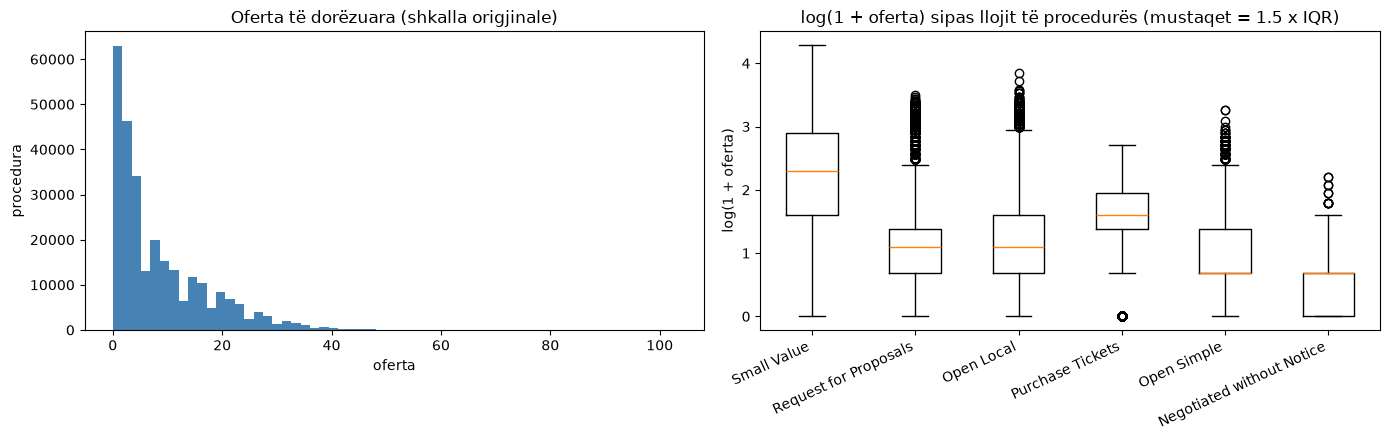

In [12]:
from src.outliers.competition_winners import GROUP, SUBMITTED, QUALIFIED

top_types = df[GROUP].value_counts().head(6).index
data = [np.log1p(df.loc[df[GROUP] == t, SUBMITTED].astype(float)) for t in top_types]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(df[SUBMITTED].astype(float), bins=60, color="steelblue")
axes[0].set(title="Oferta të dorëzuara (shkalla origjinale)", xlabel="oferta", ylabel="procedura")
axes[1].boxplot(data, whis=1.5)
axes[1].set_xticks(range(1, len(top_types) + 1), top_types, rotation=25, ha="right")
axes[1].set(title="log(1 + oferta) sipas llojit të procedurës (mustaqet = 1.5 x IQR)", ylabel="log(1 + oferta)")
plt.tight_layout()
plt.show()

Mediana e "Small Value" (9 oferta) është shumë më e lartë se e procedurave të hapura (1–2). Me një prag të vetëm global, procedurat e vogla e dominojnë shpërndarjen. Tabela më poshtë jep kufijtë për secilin grup: `upper_iqr_limit` është numri i ofertave mbi të cilin IQR e shënon procedurën.

In [13]:
from src.outliers.competition_winners import count_spread, univariate

spread = count_spread(df)
spread[spread["group"].isin(["(global)", *top_types])]

,column,group,rows,median,q1,q3,upper_iqr_limit,iqr_log,mad_log,zero_spread
0,Numri_i_ofertave_te_dorezuara,(global),277764,5.0,2.0,13.0,140.1,1.540,0.773,False
4,Numri_i_ofertave_te_dorezuara,Negotiated without Notice,5307,1.0,0.0,1.0,4.7,0.693,0.000,True
7,Numri_i_ofertave_te_dorezuara,Open Local,21980,2.0,1.0,4.0,18.8,0.916,0.405,False
8,Numri_i_ofertave_te_dorezuara,Open Simple,16725,1.0,1.0,3.0,10.3,0.693,0.693,False
9,Numri_i_ofertave_te_dorezuara,Purchase Tickets,17766,4.0,3.0,6.0,15.2,0.560,0.223,False
10,Numri_i_ofertave_te_dorezuara,Request for Proposals,25549,2.0,1.0,3.0,10.3,0.693,0.405,False
13,Numri_i_ofertave_te_dorezuara,Small Value,183329,9.0,4.0,17.0,121.9,1.281,0.693,False
14,Numri_i_ofertave_te_kualifikuara,(global),277764,3.0,1.0,8.0,84.9,1.504,0.693,False
18,Numri_i_ofertave_te_kualifikuara,Negotiated without Notice,5307,1.0,0.0,1.0,4.7,0.693,0.000,True
21,Numri_i_ofertave_te_kualifikuara,Open Local,21980,1.0,0.0,2.0,14.6,1.099,0.405,False


In [14]:
statuses, univariate_summary, global_vs_group, impossible = univariate(df)
print("Vlerat e pamundura (rregulla logjike):")
display(impossible)
univariate_summary

Vlerat e pamundura (rregulla logjike):


,check,procedures
0,Oferta të kualifikuara > të dorëzuara,0
1,Numër negativ ofertash,0
2,cpv_count negativ,0
3,"qualified_offer_share jashtë [0, 1]",0


,column,outlier_status,procedures
0,Numri_i_ofertave_te_dorezuara,gabim,0
1,Numri_i_ofertave_te_dorezuara,e vërtetë por e rrallë,559
2,Numri_i_ofertave_te_dorezuara,e pasigurt,1099
3,Numri_i_ofertave_te_dorezuara,(nuk është përjashtues),276106
4,Numri_i_ofertave_te_kualifikuara,gabim,0
5,Numri_i_ofertave_te_kualifikuara,e vërtetë por e rrallë,1054
6,Numri_i_ofertave_te_kualifikuara,e pasigurt,1696
7,Numri_i_ofertave_te_kualifikuara,(nuk është përjashtues),275014
8,cpv_count,gabim,0
9,cpv_count,e vërtetë por e rrallë,21


## 2.2 Mënjanimi i zbulimeve jo të sakta

### a) Global kundrejt brenda llojit të procedurës

In [15]:
global_vs_group

,column,flagged_global,flagged_within_group,"global_only (false detection, scale)",group_only (hidden by the global scale),both
0,Numri_i_ofertave_te_dorezuara,0,1658,0,1658,0
1,Numri_i_ofertave_te_kualifikuara,1,2750,0,2749,1
2,cpv_count,14784,13038,1746,0,13038


- Te **ofertat**, pragu global nuk gjen asnjë përjashtues, sepse "Small Value" e shtyn pragun te ≈140 oferta. Brenda llojit dalin 1,658 procedura që janë vërtet të pazakonta **për llojin e tyre**.
- Te **`cpv_count`**, 1,746 procedura shënohen vetëm globalisht, por janë normale brenda llojit të tyre. Këto janë **zbulime jo të sakta** dhe nuk merren si përjashtuese. Prandaj statusi përcaktohet nga flag-et brenda llojit.

### b) Numra diskretë: kur IQR ose MAD = 0

In [16]:
cpv = df.loc[df["cpv_count"] > 0, "cpv_count"]
print("cpv_count > 0, pjesa e secilës vlerë (%):")
print((cpv.value_counts(normalize=True).head(5) * 100).round(1).to_string())
q1, med, q3 = cpv.quantile([0.25, 0.5, 0.75])
print(f"\nQ1 = {q1:.0f}, mediana = {med:.0f}, Q3 = {q3:.0f}  ->  MAD = {(cpv - med).abs().median():.0f}")

cpv_count > 0, pjesa e secilës vlerë (%):
cpv_count
1    71.3
2    12.7
3     5.9
4     3.3
5     2.1

Q1 = 1, mediana = 1, Q3 = 2  ->  MAD = 0


71% e procedurave kanë saktësisht 1 kod CPV, prandaj MAD = 0. Me MAD = 0, z-score i modifikuar do ta bënte çdo vlerë ≠ 1 "pafundësisht larg". Në këto grupe metoda nuk aplikohet (`drop_zero_spread`), përndryshe edhe 2 kode CPV do të dilnin përjashtuese.

### c) Fituesit me shumë kontrata: të vërtetë apo gabim?

In [17]:
from src.outliers.competition_winners import winner_profile

profile = winner_profile(df)
print("Kontrata për fitues:", profile["kontrata"].describe(percentiles=[.5, .9, .99]).round(1).to_dict())
profile.head(12)

Kontrata për fitues: {'count': 7444.0, 'mean': 30.1, 'std': 130.1, 'min': 1.0, '50%': 4.0, '90%': 57.0, '99%': 463.7, 'max': 5762.0}


,NIPT_i_fituesit,fituesi,kontrata,autoritete,vite,lloje_procedure,nipt_klasa,outlier_status,interpretimi
1262,K31528061N,AMADEUS TRAWELL AND TOURS,5762,302,10,2,I vlefshëm,e vërtetë por e rrallë,"Furnitor i madh real (shumë autoritete, disa vite)"
237,J62426002Q,INFOSOFT OFFICE,4002,791,10,6,I vlefshëm,e vërtetë por e rrallë,"Furnitor i madh real (shumë autoritete, disa vite)"
1205,K31503045V,ALDOSCH - FARMA,2016,27,10,6,I vlefshëm,e vërtetë por e rrallë,"Furnitor i madh real (shumë autoritete, disa vite)"
5655,L71607034L,KELVIN TRAVEL,1795,166,8,2,I vlefshëm,e vërtetë por e rrallë,"Furnitor i madh real (shumë autoritete, disa vite)"
5510,L64704601S,SELVIJE ABASLLARI,1626,316,9,4,I vlefshëm,e vërtetë por e rrallë,"Furnitor i madh real (shumë autoritete, disa vite)"
1924,K42108801C,ALBSIG,1602,369,10,5,I vlefshëm,e vërtetë por e rrallë,"Furnitor i madh real (shumë autoritete, disa vite)"
3186,K91425009A,DORINA KARAISKAJ,1550,139,10,4,I vlefshëm,e vërtetë por e rrallë,"Furnitor i madh real (shumë autoritete, disa vite)"
3747,L12107043O,PETER PHARMA,1343,242,10,1,I vlefshëm,e vërtetë por e rrallë,"Furnitor i madh real (shumë autoritete, disa vite)"
6322,L91418502J,LIBRARI DYRRAHU,1340,525,7,5,I vlefshëm,e vërtetë por e rrallë,"Furnitor i madh real (shumë autoritete, disa vite)"
2609,K71707007Q,ERVIN LUZI,1332,438,10,5,I vlefshëm,e vërtetë por e rrallë,"Furnitor i madh real (shumë autoritete, disa vite)"


Fituesit me më shumë kontrata fitojnë te qindra autoritete dhe në 7–10 vite. P.sh. AMADEUS ka 5,762 kontrata te 302 autoritete, për bileta udhëtimi. Një gabim regjistrimi nuk do të shpërndahej kështu. Janë furnitorë realë të mëdhenj, pra **e vërtetë por e rrallë**.

### d) NIPT-et jashtë formatit shqiptar

In [18]:
from src.outliers.competition_winners import NIPT_STATUS

nipt = (profile[profile["nipt_klasa"] != "I vlefshëm"]
        .groupby("nipt_klasa").agg(fitues=("NIPT_i_fituesit", "size"), kontrata=("kontrata", "sum"),
                                   shembull=("NIPT_i_fituesit", "first")).reset_index())
nipt["outlier_status"] = nipt["nipt_klasa"].map(NIPT_STATUS)
nipt

,nipt_klasa,fitues,kontrata,shembull,outlier_status
0,Gabim shtypi në NIPT shqiptar,5,31,21406043R,gabim
1,I panjohur (vetëm shifra ose format tjetër),60,175,810802422,e pasigurt
2,Kompani e huaj (numër TVSH),14,38,SI24635812,e vërtetë por e rrallë
3,Konsorcium (NIPT të vlefshëm),158,166,J62426002Q | J72124001N,NaN
4,Konsorcium me NIPT të pavlefshëm,3,3,L71625032Q | K71728012T | K71903025A | L21508451W | L61606040D | K62029010L ...,e pasigurt


### e) Rastet e Fazës I: 5,054 anulime kontradiktore dhe 74 fitues me 0 oferta të kualifikuara

In [19]:
from src.outliers.competition_winners import review_contradictions

contradiction, reason, contradiction_summary, by_year = review_contradictions(df)
contradiction_summary

,rasti,outlier_status,procedures
0,E anuluar me vlerë kontrate: gabim sistematik i eksportit 2017,gabim,3466
1,"Arsyeja 'asnjë ofertë', por ka oferta të kualifikuara dhe fitues",gabim,1380
2,"Zbulim jo i saktë: oferta pa asnjë të kualifikuar, arsyeja do të thotë 'asnj...",(nuk është gabim),162
3,"Fitues me 0 oferta të kualifikuara, por procedura u anulua (konsistente)",e vërtetë por e rrallë,72
4,"Arsyeja 'asnjë ofertë', ka oferta, pa provë tjetër",e pasigurt,35
5,E anuluar me vlerë kontrate (mund të jetë anulim i pjesshëm),e pasigurt,11
6,Fitues me 0 oferta të kualifikuara dhe procedura nuk u anulua,gabim,2


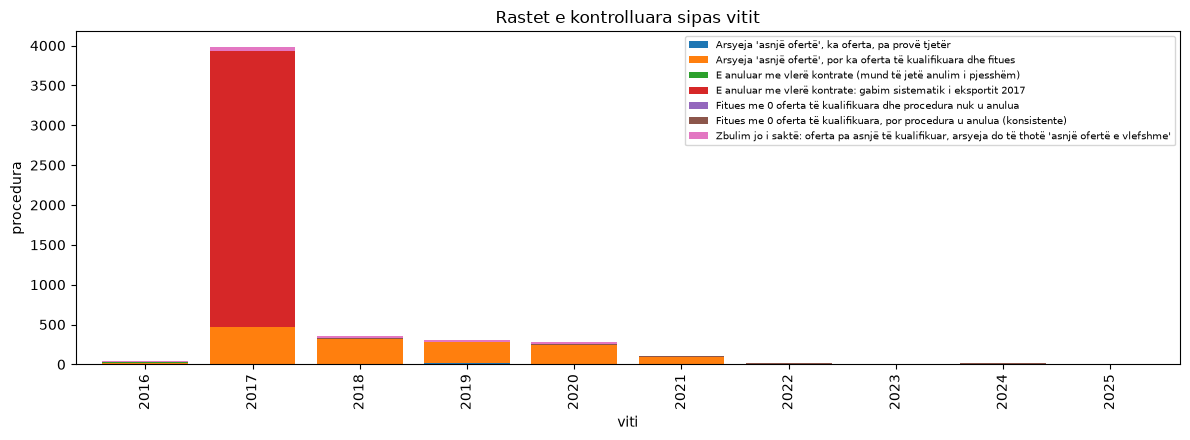

In [20]:
ax = by_year.plot(kind="bar", stacked=True, figsize=(12, 4.5), width=0.8)
ax.set(title="Rastet e kontrolluara sipas vitit", xlabel="viti", ylabel="procedura")
ax.legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

Grafiku e tregon qartë: anulimet "me kontratë të lidhur" janë pothuajse të gjitha në **2017**, me 3,466 nga 3,477. Kjo është gabim sistematik i eksportit të atij viti, jo sjellje reale. 162 rastet "asnjë ofertë" pa asnjë ofertë të kualifikuar dhe pa fitues **nuk janë kontradikta**: arsyeja do të thotë "asnjë ofertë e vlefshme". Këto janë zbulime jo të sakta të Fazës I.

## 2.3 Detektimi multivariant: distanca Mahalanobis

Mbi 9 vetitë e standardizuara të PCA-së. $D^2 = (x-\mu)^\top \Sigma^{-1} (x-\mu)$, me prag $\chi^2_{0.999}(9) = 27.877$. Mesatarja dhe kovarianca vlerësohen pa gabimet e njohura dhe pa përjashtuesit e hapit të parë, që përjashtuesit të mos e fshehin veten (efekti maskues).

In [21]:
from src.outliers.competition_winners import CHI2_999_DF9, impossible_counts, multivariate

any_impossible = pd.concat(impossible_counts(df), axis=1).any(axis=1)
multi, multi_summary, drivers, X = multivariate(df, any_impossible)
display(multi_summary)
drivers

,metric,value
0,Procedures with all 9 features,201837.000
1,"Chi-square threshold (99.9%, df=9)",27.877
2,Expected share above the threshold if normal (%),0.100
3,Known amount/count errors among them,5985.000
4,"Outliers, global",13838.000
5,"Outliers, within procedure type",14358.000
6,"Global only (false detection, scale)",1185.000
7,Group only (hidden by the global scale),1705.000
8,Status: gabim,5985.000
9,Status: e vërtetë por e rrallë,6668.000


,feature,outliers
0,Vlera_e_fituesit,4676
1,qualified_offer_share,3171
2,Fondi_limit,2849
3,kohezgjatja_e_tenderit,1533
4,cpv_count,1169
5,ditet_publikim_hapje,858
6,Numri_i_ofertave_te_kualifikuara,631
7,ditet_nga_zgjedhjet,370
8,Numri_i_ofertave_te_dorezuara,286


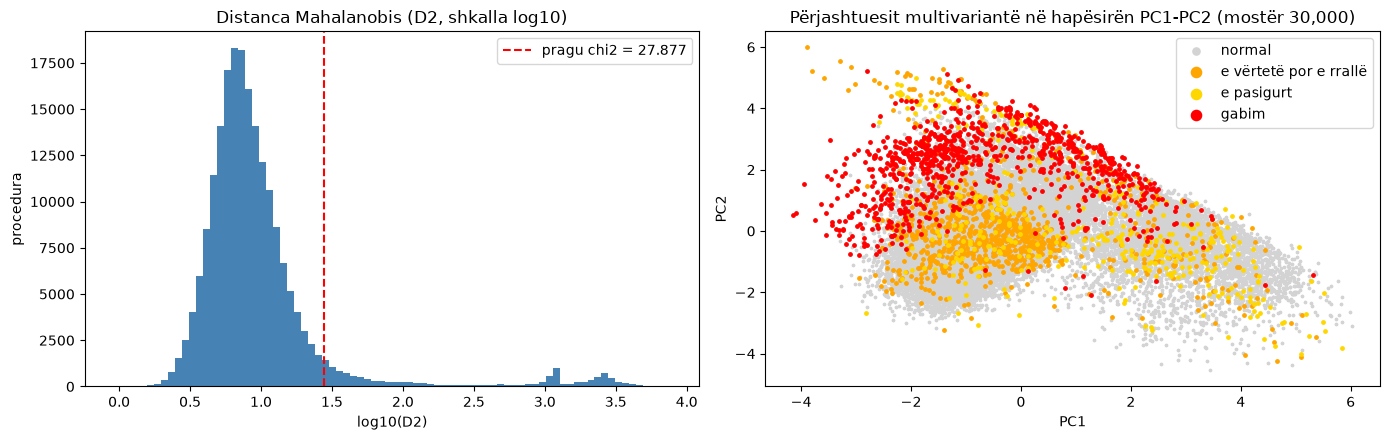

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(np.log10(multi["mahalanobis_d2"]), bins=80, color="steelblue")
axes[0].axvline(np.log10(CHI2_999_DF9), color="red", linestyle="--", label=f"pragu chi2 = {CHI2_999_DF9}")
axes[0].set(title="Distanca Mahalanobis (D2, shkalla log10)", xlabel="log10(D2)", ylabel="procedura")
axes[0].legend()

scores = df.loc[X.index, ["PC1", "PC2"]].join(multi["status"])
sample = scores.sample(30_000, random_state=42)
colors = {"e vërtetë por e rrallë": "orange", "e pasigurt": "gold", "gabim": "red"}
normal = sample[sample["status"].isna()]
axes[1].scatter(normal["PC1"], normal["PC2"], s=3, c="lightgray", label="normal")
for label, color in colors.items():
    part = sample[sample["status"] == label]
    axes[1].scatter(part["PC1"], part["PC2"], s=6, c=color, label=label)
axes[1].set(title="Përjashtuesit multivariantë në hapësirën PC1-PC2 (mostër 30,000)", xlabel="PC1", ylabel="PC2")
axes[1].legend(markerscale=3)
plt.tight_layout()
plt.show()

Me shpërndarje normale do të prisnim 0.1% mbi prag, ndërsa gjejmë 6.9%. Kjo tregon që të dhënat nuk janë normale (numra diskretë, bisht i gjatë), jo që 6.9% janë gabime. Prandaj pragu χ² përdoret si kriter seleksionimi, dhe statusi vendoset nga kombinimi global/brenda llojit dhe nga gabimet e njohura. Në PC1–PC2 shihet që shumë përjashtues nuk janë në skajet e këtyre dy komponentëve. Ata dalin jashtë në komponentët e tjerë (PC3–PC9), dhe këtë e kap Mahalanobis, por jo një grafik 2D.

### Grumbulli i dytë i D²: gabime shkalle te shumat

Histogrami ka një grumbull të dytë të ndarë, sot te log10 D² ≈ 3–3.6. Në versionin e parë të analizës (D² ≈ 250–800) këto procedura dilnin "e vërtetë por e rrallë". Kur u shqyrtuan, raporti vlerë fituese / fond limit doli ≈ 1/1000 ose ≈ 1000:

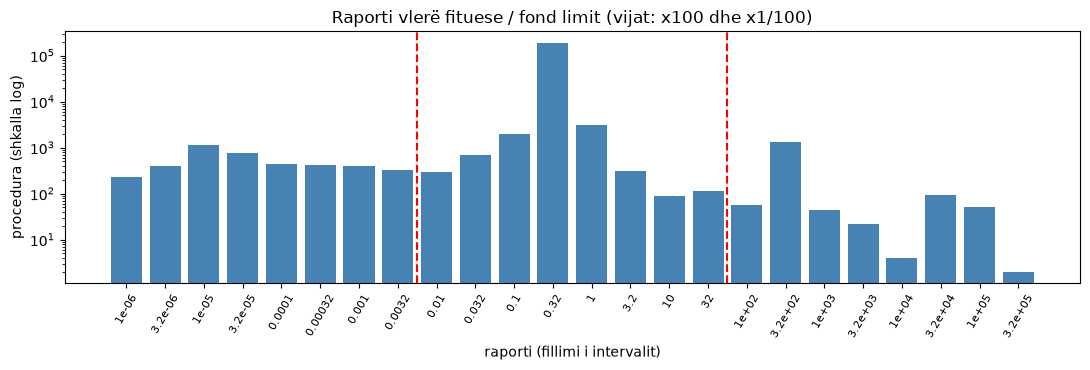

In [23]:
from src.outliers.competition_winners import SCALE_ERROR_FACTOR, value_fund_ratio_profile

ratio = value_fund_ratio_profile(df)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(range(len(ratio)), ratio["procedures"], color="steelblue")
ax.set_yscale("log")
ax.set_xticks(range(len(ratio)), [f"{r:.2g}" for r in ratio["ratio_from"]], rotation=60, fontsize=8)
for x in (np.log10(SCALE_ERROR_FACTOR), -np.log10(SCALE_ERROR_FACTOR)):
    ax.axvline((x + 6) / 0.5 - 0.5, color="red", linestyle="--")
ax.set(title=f"Raporti vlerë fituese / fond limit (vijat: x{SCALE_ERROR_FACTOR} dhe x1/{SCALE_ERROR_FACTOR})",
       xlabel="raporti (fillimi i intervalit)", ylabel="procedura (shkalla log)")
plt.tight_layout()
plt.show()

96% e procedurave kanë raport 0.1–3.2. Kulmi te ×1000 (1,340 procedura) tregon një shumë të shënuar në mijëra lekë, ndërsa poshtë 1/100 ka një bisht të veçantë. Asnjë fitues nuk fiton realisht me 1000 herë fondin, dhe as me 1% të tij. Prandaj raporti ≥ 100 ose ≤ 1/100 trajtohet si **gabim i njohur** dhe përjashtohet nga vlerësimi i mesatares dhe kovariancës. Ky është thelbi i "mënjanimit të zbulimeve jo të sakta": pa këtë kontroll, ~6,000 gabime do të raportoheshin si vlera reale.

### Kontroll me KNN (metoda nga ushtrimet)

Si në ushtrim: distanca mesatare nga 5 fqinjët më të afërt (Euklidiane, mbi të dhëna të standardizuara). Përjashtues janë pikat me distancën më të madhe. Për krahasim merret e njëjta pjesë si te Mahalanobis.

In [24]:
from sklearn.neighbors import NearestNeighbors

sample = X.sample(20_000, random_state=42)
knn = NearestNeighbors(n_neighbors=6, metric="euclidean").fit(sample)
distances, _ = knn.kneighbors(sample)
knn_distance = pd.Series(distances[:, 1:].mean(axis=1), index=sample.index)  # pa vetë pikën

maha_out = multi.loc[sample.index, "outlier_global"]
threshold = knn_distance.quantile(1 - maha_out.mean())
knn_out = knn_distance > threshold

print(pd.crosstab(maha_out, knn_out, rownames=["Mahalanobis"], colnames=["KNN"]))
print(f"\nPërjashtuesit e Mahalanobis që i gjen edhe KNN: {(maha_out & knn_out).sum() / maha_out.sum():.1%}"
      f" (rastësisht do të pritej {maha_out.mean():.1%})")
print(f"Spearman D2 kundrejt distancës KNN: {multi.loc[sample.index, 'mahalanobis_d2'].corr(knn_distance, method='spearman'):.3f}")

KNN          False  True 
Mahalanobis              
False        17865    784
True           784    567

Përjashtuesit e Mahalanobis që i gjen edhe KNN: 42.0% (rastësisht do të pritej 6.8%)
Spearman D2 kundrejt distancës KNN: 0.493


## 2.4 Eksplorimi: statistika përmbledhëse

In [25]:
from src.common.outliers import ERROR
from src.exploration.competition_winners import frequencies, summary_statistics

flags = pd.read_csv("data/processed/outliers_competition_winners.csv", low_memory=False)
flags.index = df.index
errors = flags.filter(like="outlier_status_").eq(ERROR).any(axis=1)
print(f"Procedura me të paktën një 'gabim' në këtë pjesë: {errors.sum():,}")
summary_statistics(df, errors)

Procedura me të paktën një 'gabim' në këtë pjesë: 10,795


,column,subset,n,mean,std,min,q1,median,q3,max,iqr,mad,skewness,kurtosis
0,Numri_i_ofertave_te_dorezuara,Të gjitha,277764,8.457,8.754,0.0,2.000,5.000,13.0,103.0,11.000,4.000,1.424,1.918
1,Numri_i_ofertave_te_dorezuara,Pa gabimet,266969,8.417,8.732,0.0,2.000,5.000,13.0,103.0,11.000,4.000,1.432,1.965
2,Numri_i_ofertave_te_kualifikuara,Të gjitha,277764,5.903,7.154,0.0,1.000,3.000,8.0,94.0,7.000,2.000,1.873,3.971
3,Numri_i_ofertave_te_kualifikuara,Pa gabimet,266969,5.815,7.061,0.0,1.000,3.000,8.0,94.0,7.000,2.000,1.886,4.078
4,qualified_offer_share,Të gjitha,252020,0.711,0.331,0.0,0.500,0.857,1.0,1.0,0.500,0.143,-0.771,-0.760
5,qualified_offer_share,Pa gabimet,241225,0.705,0.333,0.0,0.471,0.833,1.0,1.0,0.529,0.167,-0.744,-0.803
6,cpv_count,Të gjitha,277764,1.415,2.052,0.0,1.000,1.000,1.0,79.0,0.000,0.000,6.348,82.121
7,cpv_count,Pa gabimet,266969,1.421,2.062,0.0,1.000,1.000,1.0,79.0,0.000,0.000,6.361,82.369
8,nr_fituesve,Të gjitha,223870,1.003,0.174,1.0,1.000,1.000,1.0,35.0,0.000,0.000,99.061,12689.438
9,nr_fituesve,Pa gabimet,214319,1.003,0.177,1.0,1.000,1.000,1.0,35.0,0.000,0.000,96.924,12147.981


Te numrat mesatarja është mbi medianë dhe asimetria është pozitive, prandaj mediana dhe IQR e përshkruajnë më mirë procedurën tipike. `cpv_count` dhe `nr_fituesve` janë pothuajse konstante (Q1 = Q3 = 1) dhe kanë kurtozë shumë të madhe. Pa gabimet statistikat ndryshojnë pak, sepse gabimet e kësaj pjese janë gabime konsistence, jo vlera ekstreme.

In [26]:
freq = frequencies(df)
freq[freq["column"].isin(["competition_band", "statusi_analitik", "Tipi_i_kontrates"])]

,column,value,procedures,pct
13,Tipi_i_kontrates,Supplies,167761,60.40
14,Tipi_i_kontrates,Services,92777,33.40
15,Tipi_i_kontrates,Works,17226,6.20
16,competition_band,4+ offers,168411,60.63
17,competition_band,2-3 offers,46334,16.68
18,competition_band,Single offer,37275,13.42
19,competition_band,No offers,25744,9.27
20,statusi_analitik,"Me fitues, kontratë e pakonfirmuar",150173,54.06
21,statusi_analitik,Jo e lidhur,68371,24.61
22,statusi_analitik,Kontratë e konfirmuar,48028,17.29


## 2.5 Eksplorimi multivariant

### Krahasime sipas grupeve

,Lloji_i_procedures,procedures,mean_offers,median_offers,mean_qualified,single_bidder_pct,no_offers_pct,cancelled_pct,mean_qualified_share
12,Small Value,183329.0,11.32,9.0,7.94,8.01,4.58,26.05,0.71
9,Request for Proposals,25549.0,2.49,2.0,1.43,26.80,22.61,33.62,0.63
6,Open Local,21980.0,3.14,2.0,1.61,23.65,19.71,27.34,0.59
8,Purchase Tickets,17766.0,4.28,4.0,4.00,5.31,2.09,11.85,0.93
7,Open Simple,16725.0,2.27,1.0,1.45,30.92,21.21,29.61,0.69
3,Negotiated without Notice,5307.0,0.83,1.0,0.67,50.31,35.97,41.61,0.85
5,Open INT,5153.0,2.16,1.0,1.26,32.33,22.78,25.69,0.68
0,Consulting,1226.0,5.53,4.0,3.85,6.28,12.72,28.71,0.71


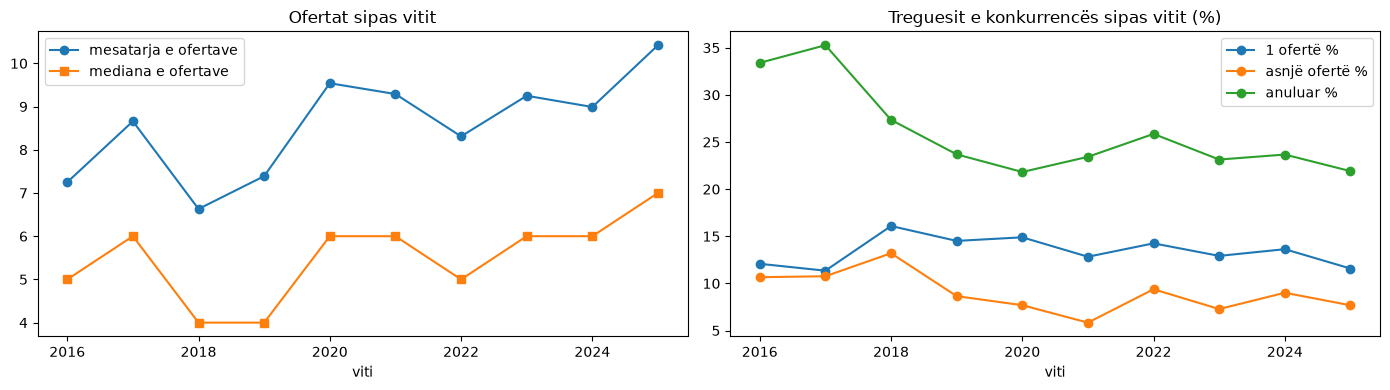

In [27]:
from src.exploration.competition_winners import competition_profile

by_type = competition_profile(df, GROUP).sort_values("procedures", ascending=False).head(8)
display(by_type)
by_year = competition_profile(df, "year")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(by_year["year"], by_year["mean_offers"], marker="o", label="mesatarja e ofertave")
axes[0].plot(by_year["year"], by_year["median_offers"], marker="s", label="mediana e ofertave")
axes[0].set(title="Ofertat sipas vitit", xlabel="viti")
axes[0].legend()
for column, label in [("single_bidder_pct", "1 ofertë %"), ("no_offers_pct", "asnjë ofertë %"), ("cancelled_pct", "anuluar %")]:
    axes[1].plot(by_year["year"], by_year[column], marker="o", label=label)
axes[1].set(title="Treguesit e konkurrencës sipas vitit (%)", xlabel="viti")
axes[1].legend()
plt.tight_layout()
plt.show()

### Tabela kryqëzimi dhe Cramér's V

Me 277,764 rreshta, testi χ² del gjithmonë i rëndësishëm (p ≈ 0), prandaj forca e lidhjes matet me Cramér's V.

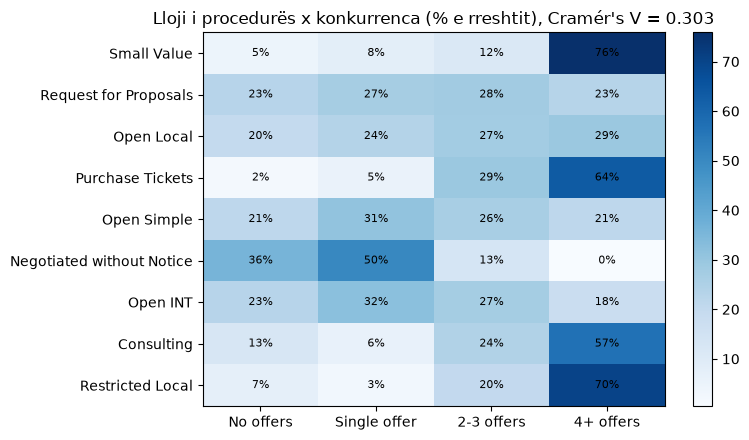

In [28]:
from src.exploration.competition_winners import crosstab_pct

table, v = crosstab_pct(df, GROUP, "competition_band")
table = table[table["procedures"] >= 500].set_index(GROUP)
bands = ["No offers", "Single offer", "2-3 offers", "4+ offers"]

fig, ax = plt.subplots(figsize=(8, 4.5))
image = ax.imshow(table[bands], cmap="Blues", aspect="auto")
ax.set_xticks(range(len(bands)), bands)
ax.set_yticks(range(len(table)), table.index)
for i in range(len(table)):
    for j, band in enumerate(bands):
        ax.text(j, i, f"{table.iloc[i][band]:.0f}%", ha="center", va="center", fontsize=8)
ax.set_title(f"Lloji i procedurës x konkurrenca (% e rreshtit), Cramér's V = {v:.3f}")
plt.colorbar(image)
plt.tight_layout()
plt.show()

In [29]:
table_cpv, v_cpv = crosstab_pct(df, "primary_cpv_division_name", "kategoria_e_fondit", top=10)
print(f"Ndarja CPV x kategoria e fondit, Cramér's V = {v_cpv:.3f}")
table_cpv

Ndarja CPV x kategoria e fondit, Cramér's V = 0.224


kategoria_e_fondit,primary_cpv_division_name,procedures,I madh,I mesëm,I vogël,Shumë i vogël
0,"Medical equipments, pharmaceuticals and personal care products",22406,24.6,15.5,20.7,39.2
1,"Office and computing machinery, equipment and supplies except furniture and ...",16056,11.3,30.6,34.1,24.0
2,Construction work,14016,57.6,24.7,11.9,5.8
3,Transport equipment and auxiliary products to transportation,10329,29.0,20.8,22.4,27.8
4,Printed matter and related products,9981,12.8,26.0,31.5,29.7
5,Repair and maintenance services,9740,19.5,28.1,28.2,24.1
6,"Petroleum products, fuel, electricity and other sources of energy",9128,31.1,32.8,25.1,11.0
7,"Furniture (incl. office furniture), furnishings, domestic appliances (excl. ...",8868,16.4,33.7,32.0,17.9
8,"Architectural, construction, engineering and inspection services",8562,20.8,20.2,23.1,35.8
9,"Electrical machinery, apparatus, equipment and consumables; lighting",8210,23.0,31.3,25.1,20.6


### Përqendrimi i tregut (HHI)

,winners,top10_share_value_pct,top10_share_contracts_pct,hhi_overall,level
0,6567,20.13,10.85,78.47,E pa përqendruar


,primary_cpv_division_name,winners,cr4_pct,hhi,level,hhi_by_contracts
0,Financial and insurance services,163,62.28,1158.88,Mesatarisht e përqendruar,1175.85
1,"Business services: law, marketing, consulting, recruitment, printing and sec...",972,40.89,914.22,E pa përqendruar,50.79
2,"Petroleum products, fuel, electricity and other sources of energy",567,44.83,707.73,E pa përqendruar,376.78
3,"Medical equipments, pharmaceuticals and personal care products",623,40.50,526.85,E pa përqendruar,330.30
4,Chemical products,589,37.26,483.22,E pa përqendruar,93.10
5,"Office and computing machinery, equipment and supplies except furniture and ...",1041,28.23,297.40,E pa përqendruar,308.79


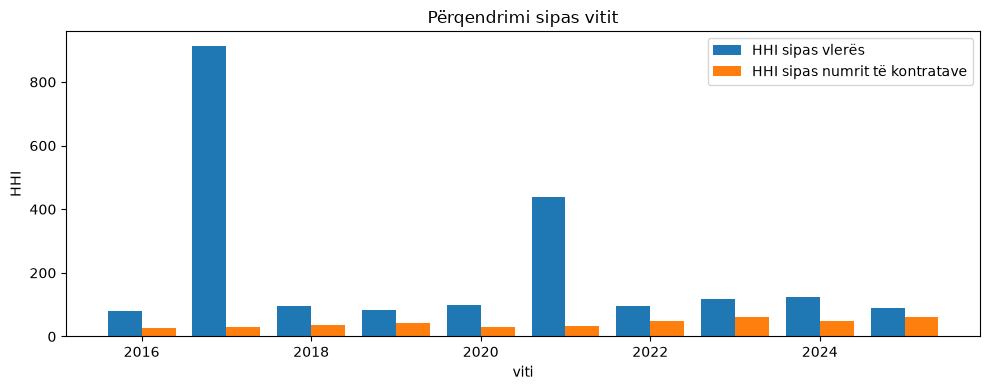

In [30]:
from src.exploration.competition_winners import concentration
from src.outliers.competition_winners import amount_errors

top_winners, hhi_cpv, hhi_year, hhi_overall = concentration(df, ~amount_errors(df))
display(hhi_overall)
display(hhi_cpv[["primary_cpv_division_name", "winners", "cr4_pct", "hhi", "level", "hhi_by_contracts"]].head(6))

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.4
ax.bar(hhi_year["year"] - width / 2, hhi_year["hhi"], width, label="HHI sipas vlerës")
ax.bar(hhi_year["year"] + width / 2, hhi_year["hhi_by_contracts"], width, label="HHI sipas numrit të kontratave")
ax.set(title="Përqendrimi sipas vitit", xlabel="viti", ylabel="HHI")
ax.legend()
plt.tight_layout()
plt.show()

Kulmet e HHI-së sipas vlerës në **2017** dhe **2021** vijnë nga dy kontrata të vetme reale: koncesioni PPP i Rrugës së Arbrit (33.6 miliardë lekë) dhe Tuneli i Llogarasë (17 miliardë). HHI sipas numrit të kontratave nuk ndryshon. Pra këto janë raste **të vërteta por të rralla**, jo gabime dhe as përqendrim i tregut.

### Korrelacioni: Pearson kundrejt Spearman, me dhe pa përjashtuesit

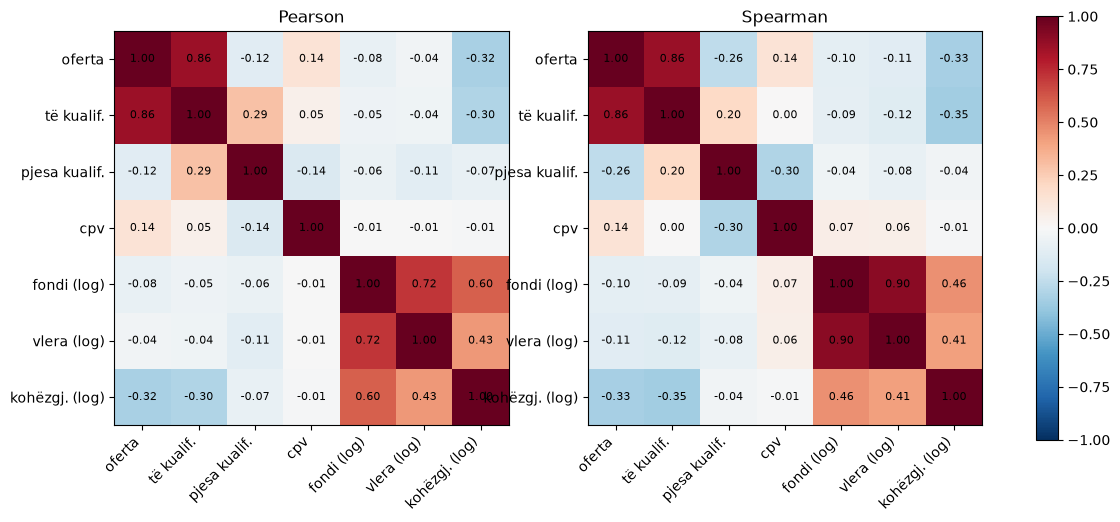

,feature_a,feature_b,pearson_all,pearson_without_outliers,spearman_all,outlier_effect,pearson_minus_spearman
18,Fondi_limit,Vlera_e_fituesit,0.718,0.993,0.904,0.274,-0.185
0,Numri_i_ofertave_te_dorezuara,Numri_i_ofertave_te_kualifikuara,0.859,0.882,0.860,0.023,-0.000
19,Fondi_limit,kohezgjatja_e_tenderit,0.598,0.674,0.457,0.076,0.141
20,Vlera_e_fituesit,kohezgjatja_e_tenderit,0.432,0.682,0.409,0.250,0.024
10,Numri_i_ofertave_te_kualifikuara,kohezgjatja_e_tenderit,-0.303,-0.299,-0.348,0.004,0.045
5,Numri_i_ofertave_te_dorezuara,kohezgjatja_e_tenderit,-0.324,-0.315,-0.333,0.010,0.009
11,qualified_offer_share,cpv_count,-0.145,-0.167,-0.303,-0.022,0.159
1,Numri_i_ofertave_te_dorezuara,qualified_offer_share,-0.115,-0.083,-0.256,0.032,0.142


In [31]:
from src.exploration.competition_winners import correlations

pearson, spearman, pairs = correlations(df, flags["outlier_status_multivariant"].notna())
labels = ["oferta", "të kualif.", "pjesa kualif.", "cpv", "fondi (log)", "vlera (log)", "kohëzgj. (log)"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, matrix, title in [(axes[0], pearson, "Pearson"), (axes[1], spearman, "Spearman")]:
    image = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)
plt.colorbar(image, ax=axes)
plt.show()
pairs.head(8)

Pearson fond–vlerë është **0.72** me të gjitha procedurat dhe **0.99** pa përjashtuesit multivariantë, ndërsa Spearman (rangje) është 0.90. Pak procedura ku fondi dhe vlera nuk përputhen fare e ulin fort Pearson. Kjo e tregon pse përjashtuesit duhen trajtuar para analizës. Tenderët më të gjatë kanë më pak oferta (ρ ≈ −0.33).

### Interpretimi i komponentëve të PCA-së

In [32]:
from src.exploration.competition_winners import pca_interpretation

pca_interpretation(df)

,component,explained_variance_pct,largest_loadings,interpretation
0,PC1,29.19,"kohezgjatja_e_tenderit (+0.50), Fondi_limit (+0.44), Numri_i_ofertave_te_kua...",Madhësia dhe kompleksiteti kundrejt konkurrencës: fond/vlerë e madhe dhe ten...
1,PC2,18.53,"Numri_i_ofertave_te_dorezuara (-0.56), Numri_i_ofertave_te_kualifikuara (-0....",Shkalla e përgjithshme: shumë oferta dhe shuma të mëdha bashkë
2,PC3,14.46,"qualified_offer_share (-0.72), cpv_count (+0.57), Numri_i_ofertave_te_kualif...",Cilësia e ofertave: pjesa e kualifikuar e ulët kundrejt shumë kodeve CPV
3,PC4,11.38,"ditet_nga_zgjedhjet (-0.88), ditet_publikim_hapje (-0.37), cpv_count (-0.24)",Afërsia me zgjedhjet (ditet_nga_zgjedhjet)
4,PC5,9.95,"ditet_publikim_hapje (+0.85), ditet_nga_zgjedhjet (-0.44), Vlera_e_fituesit ...",Koha nga publikimi deri te hapja
5,PC6,8.56,"cpv_count (+0.74), qualified_offer_share (+0.55), ditet_publikim_hapje (-0.25)",Shumë kode CPV me pjesë të lartë ofertash të kualifikuara


## 2.6 Përfundime (pjesa e Tringës)

1. **Numrat e ofertave nuk kanë vlera të pamundura.** Përjashtuesit e tyre janë relativë ndaj llojit të procedurës. Pragu global nuk gjen asgjë, ndërsa brenda llojit gjenden 1,658 procedura me konkurrencë të pazakontë.
2. **Zbulimet jo të sakta u hoqën në katër mënyra:** (a) 1,746 flag-e globale të `cpv_count` që janë normale brenda llojit; (b) grupet ku IQR/MAD = 0 nuk testohen; (c) 162 "kontradikta" të Fazës I nuk janë kontradikta; (d) fituesit me mijëra kontrata janë furnitorë realë.
3. **Gabimet reale** janë gabime konsistence (3,466 anulime me kontratë nga eksporti i 2017, 1,380 arsye "asnjë ofertë" me fitues), gabime shkalle vlerë/fond dhe 5 NIPT me gabim shtypi.
4. **Multivariant:** Mahalanobis i gjen të 5,985 gabimet e njohura (100%), dhe kontrolli me KNN e konfirmon (≈6.2 herë më shumë përputhje se rastësia). Grumbulli i dytë i D² zbuloi ~6,000 gabime shkalle vlerë/fond (×1000), që përndryshe do të dilnin "të vërteta".
5. **Eksplorimi:** lloji i procedurës është faktori kryesor i konkurrencës (V = 0.30). Tregu në tërësi nuk është i përqendruar (HHI = 78), me përjashtim të sigurimeve (HHI = 1,160). PC1–PC2 përshkruajnë madhësinë kundrejt konkurrencës.